# JAXcosmo: autodiff vs finite differences vs standard backends

Photometric `GCph` + `WL` forecast for the same fiducial cosmology and the same survey
specifications (`Euclid-Photometric-ISTF-Pessimistic`), flat LCDM with massless neutrinos.

| label | theory | observable | derivatives |
|---|---|---|---|
| **JAXcosmo AD** | `jaxcosmo` (Eisenstein–Hu + Halofit) | CosmicFishPie photometry, JAX re-implementation | `jax.jacfwd` |
| **JAXcosmo FD** | `jaxcosmo` | the same JAX observable | finite differences (standard engine) |
| **JAXcosmo legacy FD** | `jaxcosmo` | standard NumPy/SciPy `ComputeCls` | finite differences |
| **SYREN FD** | `symbolic` / SYREN-NEW | standard NumPy/SciPy `ComputeCls` | finite differences |

Two separate questions are being answered:

* **Autodiff vs finite differences** — `JAXcosmo AD` versus `JAXcosmo FD`: identical theory and
  identical observable, only the derivative route changes.
* **Theory backend** — `JAXcosmo legacy FD` versus `SYREN FD`, plus the theory comparison below.

**Naming clarification.** `JaxPhotoObservable` is CosmicFishPie's own photometric observable
(`ComputeCls` in `cosmicfishpie/LSSsurvey/photo_obs.py`) re-implemented with `jax.numpy` so that
it can be traced. It is *not* a wrapper around `ComputeCls` and it is *not*
`jax_cosmo.angular_cl`.

**Eisenstein–Hu caveat.** SYREN-NEW's *linear* emulator is built on the no-wiggle
Eisenstein–Hu shape plus fitted corrections (Bartlett et al. 2023) and its own growth model;
its nonlinear spectrum is a separate emulator. The `jaxcosmo` backend uses the Eisenstein–Hu
transfer function *with* baryon wiggles, the `symbolic_pofk` $A_s \to \sigma_8$ fit and Halofit.
Sharing the Eisenstein–Hu ingredient therefore does **not** make the two theories identical —
the theory section below shows the actual size of the difference.

In [11]:
%matplotlib inline
import os

os.environ.setdefault("OMP_NUM_THREADS", "8")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import hashlib
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
for parent in (ROOT, *ROOT.parents):
    if (parent / "cosmicjellyfish" / "LSSsurvey").is_dir():
        ROOT = parent
        break
sys.path.insert(0, str(ROOT))

from cosmicjellyfish.analysis.fishconsumer import FishConsumer
from cosmicjellyfish.analysis.fisher_matrix import fisher_matrix
from cosmicjellyfish.cosmology.jaxcosmo_theory import JaxCosmoTheory, enable_x64
from cosmicjellyfish.fishermatrix.cosmicfish import FisherMatrix
from cosmicjellyfish.fishermatrix.jaxcosmo_derivatives import (
    JaxAutodiffProvider,
    JaxFiniteDifferenceProvider,
)
from cosmicjellyfish.LSSsurvey import photo_obs
from cosmicjellyfish.LSSsurvey.jaxcosmo_photo import JaxPhotoObservable
from cosmicjellyfish.version import VERSION

enable_x64()  # before any JAX array is created

RESULT_DIR = ROOT / "results" / "jaxcosmo_ad_vs_fd"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
SPECS_DIR = ROOT / "cosmicjellyfish" / "configs" / "default_survey_specifications"
YAML_DIR = ROOT / "cosmicjellyfish" / "configs" / "default_boltzmann_yaml_files"

import jax
import jax_cosmo
import symbolic_pofk
import symbolic_pofk.syren_new as syren_new

pd.set_option("display.width", 160)
pd.set_option("display.precision", 6)

print("cosmicjellyfish", VERSION)
print("jax", jax.__version__, "| devices", jax.devices())
print("jax_cosmo", getattr(jax_cosmo, "__version__", "unknown"))
print("symbolic_pofk", getattr(symbolic_pofk, "__version__", "unknown"))
print("syren_new.py", syren_new.__file__)
print("syren_new.py sha256", hashlib.sha256(Path(syren_new.__file__).read_bytes()).hexdigest())

cosmicfishpie 1.3.1
jax 0.12.0.1 | devices [CpuDevice(id=0)]
jax_cosmo 0.1.0
symbolic_pofk unknown
syren_new.py /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/.venv/lib/python3.12/site-packages/symbolic_pofk/syren_new.py
syren_new.py sha256 3615ab2e2760cdffc5c10c4d9273a374797756b0003fa9e83b37b3be11ce08b7


## Fiducial cosmology and common settings

The fiducial point matches the JAXcosmo parity work: $10^9 A_s = 2.1$, $\Omega_m = 0.32$,
$\Omega_b = 0.05$, $h = 0.67$, $n_s = 0.96$, massless neutrinos, flat LCDM.
`mnu = 0` is currently the only domain supported by the `jaxcosmo` backend.

Each run gets a **fresh** options dictionary: `cfg.init` fills defaults into the dictionary it
receives, so reusing one dictionary across backends would leak settings.

In [12]:
FIDUCIAL = {"10^9As": 2.1, "Omegam": 0.32, "Omegab": 0.05, "h": 0.67, "ns": 0.96, "mnu": 0.0}
FREE = {name: 0.01 for name in ("10^9As", "Omegam", "Omegab", "h")}
OBSERVABLES = ["GCph", "WL"]
SURVEY_PHOTO = "Euclid-Photometric-ISTF-Pessimistic"
SYREN_PROFILE = YAML_DIR / "symbolic" / "syren_new_photo.yaml"


def options_for(tag, code, *, extra=None):
    options = {
        "accuracy": 1,
        "derivatives": "3PT",
        "feedback": 0,
        "nonlinear": True,
        "survey_name": "Euclid",
        "survey_name_photo": SURVEY_PHOTO,
        "specs_dir": str(SPECS_DIR) + "/",
        "cosmo_model": "LCDM",
        "code": code,
        "results_dir": str(RESULT_DIR / tag) + "/",
        "outroot": "jaxcosmo_" + tag,
    }
    if code == "symbolic":
        options["symbolic_config_yaml"] = str(SYREN_PROFILE)
    options.update(extra or {})
    return options


def make_calc(tag, code, *, provider=None, step=0.01, extra=None):
    return FisherMatrix(
        options=options_for(tag, code, extra=extra),
        fiducialpars=dict(FIDUCIAL),
        freepars={name: step for name in FREE},
        observables=OBSERVABLES,
        cosmoModel="LCDM",
        surveyName="Euclid",
        derivative_provider=provider,
    )

## Theory comparison: what the two backends actually predict

Left: linear matter power at $z=0$. Right: nonlinear matter power at $z=0$.

The dashed `jaxcosmo` curve is the same Eisenstein–Hu transfer function *without* baryon
wiggles, and the dotted curve is the raw no-wiggle Eisenstein–Hu spectrum that SYREN's linear
emulator is built on. These two are shown to make the "shared Eisenstein–Hu" idea concrete:
they agree in shape at the percent level, but they are only the *starting point* of SYREN.
The solid curves are the actual theory predictions used in the forecasts.

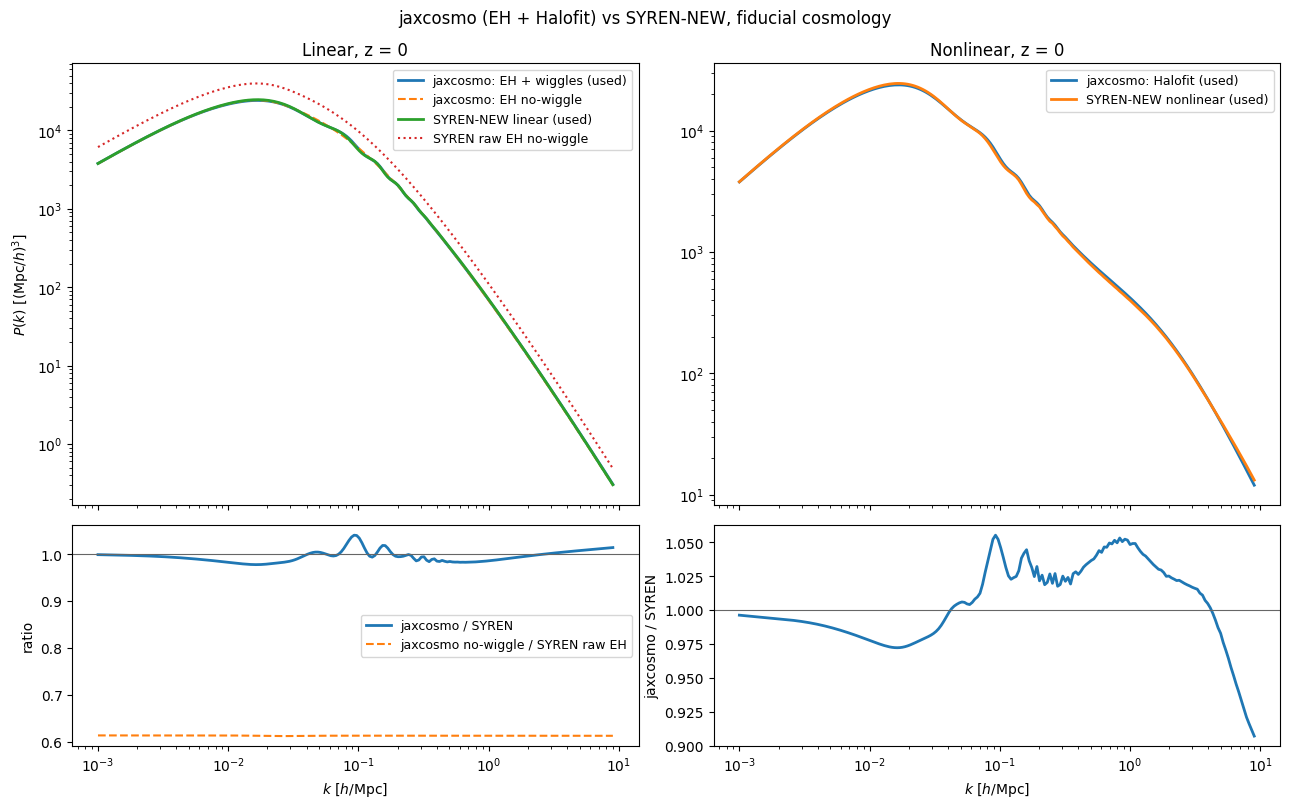

max |P_jax/P_syren - 1| linear    = 4.124e-02
max |P_jax/P_syren - 1| nonlinear = 9.269e-02


In [13]:
H = FIDUCIAL["h"]
COSMO = {
    "As": FIDUCIAL["10^9As"],
    "Omegam": FIDUCIAL["Omegam"],
    "Omegab": FIDUCIAL["Omegab"],
    "h": FIDUCIAL["h"],
    "ns": FIDUCIAL["ns"],
    "w0": -1.0,
    "wa": 0.0,
}
Z_THEORY = np.array([0.0, 0.5, 1.0])
K_HMPC = np.logspace(np.log10(1e-3), np.log10(9.0), 200)
IZ = 0  # z = 0

theory = JaxCosmoTheory(cosmo_model="LCDM")
theory_no_wiggle = JaxCosmoTheory(
    backend_parameters={"ACCURACY": {"transfer": "eisenhu"}}, cosmo_model="LCDM"
)
tables = theory.tables(COSMO, Z_THEORY, K_HMPC, nonlinear=True)
tables_nw = theory_no_wiggle.tables(COSMO, Z_THEORY, K_HMPC, nonlinear=False)

from symbolic_pofk.linear_new import get_eisensteinhu_nw, plin_new_emulated
from symbolic_pofk.syren_new import pnl_new_emulated

syren_args = (
    FIDUCIAL["10^9As"], FIDUCIAL["Omegam"], FIDUCIAL["Omegab"], H, FIDUCIAL["ns"],
    FIDUCIAL["mnu"], -1.0, 0.0,
)  # fmt: skip
syren_lin = plin_new_emulated(K_HMPC, *syren_args, a=1.0)
syren_nl = pnl_new_emulated(K_HMPC, *syren_args, a=1.0)
syren_eh_nw = get_eisensteinhu_nw(K_HMPC, *syren_args)

# jaxcosmo returns Mpc^3, SYREN (Mpc/h)^3.
jax_lin_h = np.asarray(tables.pk_linear[IZ]) * H**3
jax_nl_h = np.asarray(tables.pk_nonlinear[IZ]) * H**3
jax_nw_h = np.asarray(tables_nw.pk_linear[IZ]) * H**3

fig, axes = plt.subplots(2, 2, figsize=(13, 8.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0, 0]
ax.loglog(K_HMPC, jax_lin_h, lw=2, label="jaxcosmo: EH + wiggles (used)")
ax.loglog(K_HMPC, jax_nw_h, ls="--", label="jaxcosmo: EH no-wiggle")
ax.loglog(K_HMPC, syren_lin, lw=2, label="SYREN-NEW linear (used)")
ax.loglog(K_HMPC, syren_eh_nw, ls=":", label="SYREN raw EH no-wiggle")
ax.set_ylabel(r"$P(k)\ [({\rm Mpc}/h)^3]$")
ax.set_title("Linear, z = 0")
ax.legend(fontsize=9)

ax = axes[1, 0]
ax.semilogx(K_HMPC, jax_lin_h / syren_lin, lw=2, label="jaxcosmo / SYREN")
ax.semilogx(K_HMPC, jax_nw_h / syren_eh_nw, ls="--", label="jaxcosmo no-wiggle / SYREN raw EH")
ax.axhline(1.0, color="0.4", lw=0.8)
ax.set_xlabel(r"$k\ [h/{\rm Mpc}]$")
ax.set_ylabel("ratio")
ax.legend(fontsize=9)

ax = axes[0, 1]
ax.loglog(K_HMPC, jax_nl_h, lw=2, label="jaxcosmo: Halofit (used)")
ax.loglog(K_HMPC, syren_nl, lw=2, label="SYREN-NEW nonlinear (used)")
ax.set_title("Nonlinear, z = 0")
ax.legend(fontsize=9)

ax = axes[1, 1]
ax.semilogx(K_HMPC, jax_nl_h / syren_nl, lw=2)
ax.axhline(1.0, color="0.4", lw=0.8)
ax.set_xlabel(r"$k\ [h/{\rm Mpc}]$")
ax.set_ylabel("jaxcosmo / SYREN")

fig.suptitle("jaxcosmo (EH + Halofit) vs SYREN-NEW, fiducial cosmology")
fig.tight_layout()
fig.savefig(RESULT_DIR / "theory_comparison.png", dpi=140, bbox_inches="tight")
plt.show()

print(f"max |P_jax/P_syren - 1| linear    = {np.max(np.abs(jax_lin_h / syren_lin - 1)):.3e}")
print(f"max |P_jax/P_syren - 1| nonlinear = {np.max(np.abs(jax_nl_h / syren_nl - 1)):.3e}")

### Response to the spectral index

A Fisher forecast for `ns` is controlled by $\partial \ln P/\partial n_s$ at fixed $A_s$, not by
the amplitude of $P(k)$. This panel shows how different the two theory models are in exactly the
quantity the derivative uses.

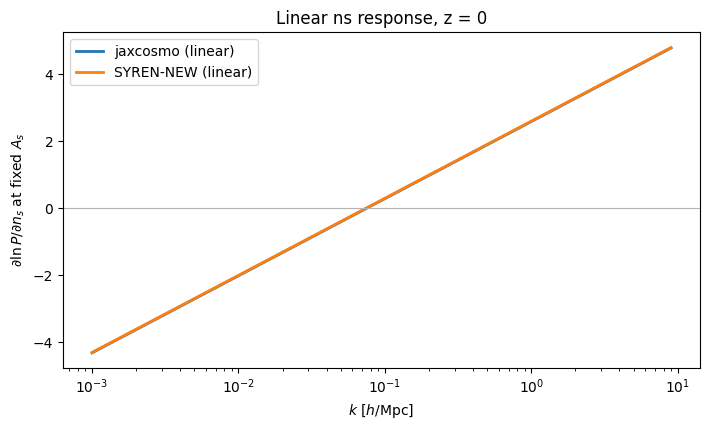

In [14]:
DNS = 0.0096
params_p = dict(COSMO, ns=COSMO["ns"] + DNS)
params_m = dict(COSMO, ns=COSMO["ns"] - DNS)
z0 = np.array([0.0])
jp = theory.tables(params_p, z0, K_HMPC, nonlinear=False).pk_linear[0]
jm = theory.tables(params_m, z0, K_HMPC, nonlinear=False).pk_linear[0]
dlnp_jax = (np.log(np.asarray(jp)) - np.log(np.asarray(jm))) / (2.0 * DNS)

syren_p = plin_new_emulated(K_HMPC, syren_args[0], syren_args[1], syren_args[2], syren_args[3],
                            syren_args[4] + DNS, *syren_args[5:], a=1.0)
syren_m = plin_new_emulated(K_HMPC, syren_args[0], syren_args[1], syren_args[2], syren_args[3],
                            syren_args[4] - DNS, *syren_args[5:], a=1.0)
dlnp_syren = (np.log(syren_p) - np.log(syren_m)) / (2.0 * DNS)

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.semilogx(K_HMPC, dlnp_jax, lw=2, label="jaxcosmo (linear)")
ax.semilogx(K_HMPC, dlnp_syren, lw=2, label="SYREN-NEW (linear)")
ax.axhline(0.0, color="0.7", lw=0.8)
ax.set_xlabel(r"$k\ [h/{\rm Mpc}]$")
ax.set_ylabel(r"$\partial \ln P/\partial n_s$ at fixed $A_s$")
ax.set_title("Linear ns response, z = 0")
ax.legend()
fig.tight_layout()
fig.savefig(RESULT_DIR / "ns_response.png", dpi=140, bbox_inches="tight")
plt.show()

## Angular power spectra: JAX observable vs standard observable

Both use the `jaxcosmo` theory, so any difference here is purely the observable implementation.

JAX C_ell (compiled call): 3.56 s
400 spectra compared: max |dC|/max|C| = 2.069e-05


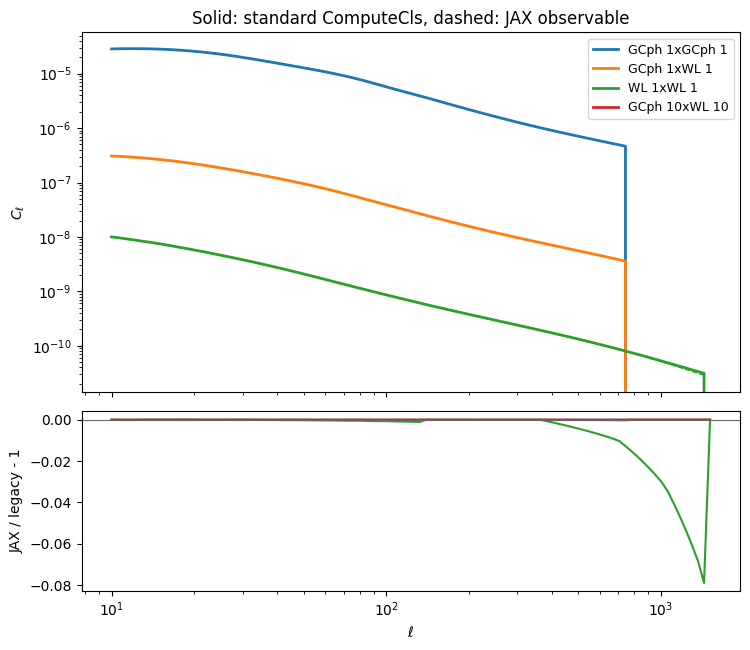

In [15]:
reference = make_calc("reference", "jaxcosmo")
legacy_obs = photo_obs.ComputeCls(
    reference.fiducialcosmopars,
    reference.photopars,
    reference.IApars,
    reference.photobiaspars,
    configuration=reference,
)
legacy_obs.compute_all()
jax_obs = JaxPhotoObservable(reference, dict(reference.allparams_fidus))
t0 = time.time()
jax_cls = jax_obs.cls()
print(f"JAX C_ell (compiled call): {time.time() - t0:.2f} s")

ells = legacy_obs.result["ells"]
keys_to_plot = ["GCph 1xGCph 1", "GCph 1xWL 1", "WL 1xWL 1", "GCph 10xWL 10"]
all_keys = [k for k in legacy_obs.result if k != "ells"]
scale = max(np.max(np.abs(legacy_obs.result[k])) for k in all_keys)
max_rel = max(
    np.max(np.abs(np.asarray(jax_cls[k]) - legacy_obs.result[k])) / scale for k in all_keys
)
print(f"{len(all_keys)} spectra compared: max |dC|/max|C| = {max_rel:.3e}")

fig, axes = plt.subplots(2, 1, figsize=(7.6, 6.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for key in keys_to_plot:
    line = axes[0].loglog(ells, legacy_obs.result[key], lw=2, label=key)
    axes[0].loglog(
        ells, jax_cls[key], lw=1, ls="--", color=line[0].get_color(),
    )
    reference_cl = np.asarray(legacy_obs.result[key])
    ratio = np.divide(
        np.asarray(jax_cls[key]), reference_cl, out=np.ones_like(reference_cl), where=reference_cl != 0
    )
    axes[1].semilogx(ells, ratio - 1.0)
axes[1].axhline(0.0, color="0.4", lw=0.8)
axes[1].set_xlabel(r"$\ell$")
axes[1].set_ylabel("JAX / legacy - 1")
axes[0].set_ylabel(r"$C_\ell$")
axes[0].set_title("Solid: standard ComputeCls, dashed: JAX observable")
axes[0].legend(fontsize=9)
fig.tight_layout()
fig.savefig(RESULT_DIR / "cls_comparison.png", dpi=140, bbox_inches="tight")
plt.show()

## Fisher matrices

Four runs, all with the same 4 free cosmological parameters (`10^9As`, `Omegam`,
`Omegab`, `h`; relative step 1%, standard `3PT` stencil) and the same 13 nuisance
parameters. `ns = 0.96` is held fixed because of the known SYREN-NEW nonlinear
spectral-index response discrepancy. The response diagnostic above still varies
`ns` independently of the Fisher parameter list.

In [16]:
RUNS = [
    ("jaxcosmo_ad", "jaxcosmo", JaxAutodiffProvider(), 0.01),
    ("jaxcosmo_fd", "jaxcosmo", JaxFiniteDifferenceProvider(), 0.01),
    ("jaxcosmo_legacy_fd", "jaxcosmo", None, 0.01),
    ("syren_fd", "symbolic", None, 0.01),
]

results = {}
for tag, code, provider, step in RUNS:
    calc = make_calc(tag, code, provider=provider, step=step)
    t0 = time.time()
    output = calc.compute()
    elapsed = time.time() - t0
    fm = fisher_matrix(file_name=str(output.file_name))
    results[tag] = {
        "fisher": fm,
        "curve": np.asarray(fm.get_fisher_matrix(), dtype=float),
        "file": str(output.file_name),
        "seconds": elapsed,
        "code": calc.input_type,
    }
    print(f"{tag:22s} code={calc.input_type:9s} {elapsed:6.1f}s  -> {output.file_name}")


  Fisher matrix exported: /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/results/jaxcosmo_ad_vs_fd/jaxcosmo_ad//CosmicFish_v1.3.1_jaxcosmo_jaxcosmo_ad_GCphWL_FM.txt

jaxcosmo_ad            code=jaxcosmo    19.1s  -> /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/results/jaxcosmo_ad_vs_fd/jaxcosmo_ad//CosmicFish_v1.3.1_jaxcosmo_jaxcosmo_ad_GCphWL_FM.txt

  Fisher matrix exported: /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/results/jaxcosmo_ad_vs_fd/jaxcosmo_fd//CosmicFish_v1.3.1_jaxcosmo_jaxcosmo_fd_GCphWL_FM.txt

jaxcosmo_fd            code=jaxcosmo     4.5s  -> /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/results/jaxcosmo_ad_vs_fd/jaxcosmo_fd//CosmicFish_v1.3.1_jaxcosmo_jaxcosmo_fd_GCphWL_FM.txt

  Fisher matrix exported: /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/results/jaxcosmo_ad_vs_fd/jaxcosmo_legacy_fd//CosmicFish_v1.3.1_jaxcosmo_jaxcosmo_legacy_fd_GCphWL_FM.txt

jaxcosmo_legacy_fd     code=jaxcosmo 

### Autodiff vs finite differences: step-size convergence

The finite differences are repeated with smaller steps. If autodiff is the exact derivative of
the implemented function, the `JAXcosmo FD` result must converge *towards* `JAXcosmo AD` as the
step shrinks.

In [17]:
def fisher_max_diff(candidate, reference):
    scale = float(np.max(np.abs(reference)))
    return float(np.max(np.abs(candidate - reference)) / scale) if scale else float("nan")


def sigma_vector(fisher, names):
    covariance = fisher.get_fisher_inverse()
    full = list(fisher.get_param_names())
    idx = [full.index(name) for name in names]
    return np.sqrt(np.diag(covariance))[idx]


ad_sigma = sigma_vector(results["jaxcosmo_ad"]["fisher"], list(FREE))
convergence = []
for tag, step in (("jaxcosmo_fd", 0.01), ("jaxcosmo_fd_step1e-3", 1.0e-3), ("jaxcosmo_fd_step1e-4", 1.0e-4)):
    if tag not in results:
        calc = make_calc(tag, "jaxcosmo", provider=JaxFiniteDifferenceProvider(), step=step)
        t0 = time.time()
        output = calc.compute()
        fm = fisher_matrix(file_name=str(output.file_name))
        results[tag] = {
            "fisher": fm,
            "curve": np.asarray(fm.get_fisher_matrix(), dtype=float),
            "file": str(output.file_name),
            "seconds": time.time() - t0,
            "code": calc.input_type,
        }
    sigma = sigma_vector(results[tag]["fisher"], list(FREE))
    convergence.append(
        {
            "fd_step": step,
            "max|dF|/max|F| vs AD": fisher_max_diff(results[tag]["curve"], results["jaxcosmo_ad"]["curve"]),
            "max rel. sigma diff vs AD": float(np.max(np.abs(sigma / ad_sigma - 1.0))),
            "seconds": results[tag]["seconds"],
        }
    )
pd.DataFrame(convergence).set_index("fd_step")


  Fisher matrix exported: /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/results/jaxcosmo_ad_vs_fd/jaxcosmo_fd_step1e-3//CosmicFish_v1.3.1_jaxcosmo_jaxcosmo_fd_step1e-3_GCphWL_FM.txt


  Fisher matrix exported: /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/results/jaxcosmo_ad_vs_fd/jaxcosmo_fd_step1e-4//CosmicFish_v1.3.1_jaxcosmo_jaxcosmo_fd_step1e-4_GCphWL_FM.txt



,max|dF|/max|F| vs AD,max rel. sigma diff vs AD,seconds
fd_step,,,
1.000000000E-02,1.806033707E-05,2.393798586E-04,4.468983173E+00
1.000000000E-03,1.806334937E-07,6.580859881E-06,4.484042883E+00
1.000000000E-04,4.205494868E-08,4.253351378E-06,4.885213137E+00


## Results

In [20]:
rows = {}
for tag, data in results.items():
    sigma = sigma_vector(data["fisher"], list(FREE))
    row = dict(zip(FREE, sigma))
    row["seconds"] = data["seconds"]
    rows[tag] = row
sigma_table = pd.DataFrame(rows).T
sigma_table

,10^9As,Omegam,Omegab,h,seconds
jaxcosmo_ad,2.640811095E-02,2.488517052E-03,2.032273048E-03,1.068436941E-02,1.909921050E+01
jaxcosmo_fd,2.640648887E-02,2.487921351E-03,2.032363330E-03,1.068267408E-02,4.468983173E+00
jaxcosmo_legacy_fd,2.639826581E-02,2.479157458E-03,2.032260166E-03,1.068081550E-02,4.030461073E+00
syren_fd,2.943957577E-02,2.381679441E-03,1.949985966E-03,1.059645590E-02,5.385187626E+00
jaxcosmo_fd_step1e-3,2.640808539E-02,2.488500675E-03,2.032273915E-03,1.068434823E-02,4.484042883E+00
jaxcosmo_fd_step1e-4,2.640810129E-02,2.488506468E-03,2.032273010E-03,1.068436490E-02,4.885213137E+00


In [21]:
legacy = results["jaxcosmo_legacy_fd"]["curve"]
rows = []
for tag, data in results.items():
    rows.append(
        {
            "variant": tag,
            "max|dF|/max|F| vs legacy FD": fisher_max_diff(data["curve"], legacy),
            "max|dF|/max|F| vs AD": fisher_max_diff(data["curve"], results["jaxcosmo_ad"]["curve"]),
        }
    )
pd.DataFrame(rows).set_index("variant")

,max|dF|/max|F| vs legacy FD,max|dF|/max|F| vs AD
variant,,
jaxcosmo_ad,1.192346513E-03,0.000000000E+00
jaxcosmo_fd,1.174611235E-03,1.806033707E-05
jaxcosmo_legacy_fd,0.000000000E+00,1.193769901E-03
syren_fd,4.773828789E-02,4.660150652E-02
jaxcosmo_fd_step1e-3,1.192169161E-03,1.806334937E-07
jaxcosmo_fd_step1e-4,1.192344736E-03,4.205494868E-08


Plot saved to: /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/results/jaxcosmo_ad_vs_fd/triangle_ad_fd_legacy_syren.png


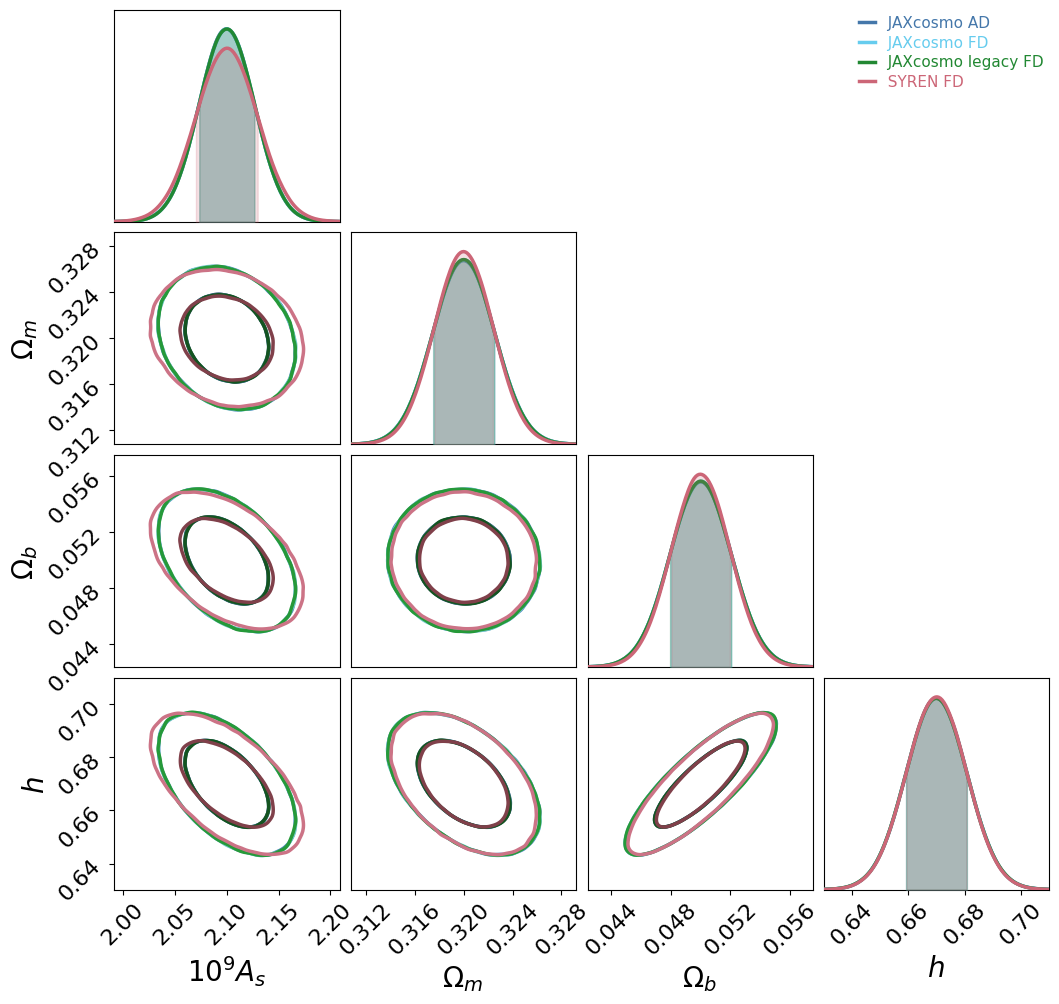

In [22]:
params = list(FREE)
labels = ["JAXcosmo AD", "JAXcosmo FD", "JAXcosmo legacy FD", "SYREN FD"]
colors = ["#4477aa", "#66ccee", "#228833", "#cc6677"]
fishers = [results[tag]["fisher"] for tag in ("jaxcosmo_ad", "jaxcosmo_fd", "jaxcosmo_legacy_fd", "syren_fd")]

triangle_path = RESULT_DIR / "triangle_ad_fd_legacy_syren.png"
FishConsumer().make_triangle_plot(
    fishers=fishers,
    fisher_labels=labels,
    params=params,
    colors=colors,
    param_labels={
        "10^9As": r"$10^9 A_s$",
        "Omegam": r"$\Omega_m$",
        "Omegab": r"$\Omega_b$",
        "h": r"$h$",
        "ns": r"$n_s$",
    },
    legend_kwargs={"fontsize": 11, "loc": "upper right"},
    save_plot=True,
    savefile=str(triangle_path),
)
plt.show()

In [23]:
summary = {
    "fiducial": FIDUCIAL,
    "freeparams": FREE,
    "survey": SURVEY_PHOTO,
    "cosmo_model": "LCDM",
    "versions": {
        "cosmicjellyfish": VERSION,
        "jax": jax.__version__,
        "jax_cosmo": getattr(jax_cosmo, "__version__", "unknown"),
        "symbolic_pofk": getattr(symbolic_pofk, "__version__", "unknown"),
    },
    "syren_new": {
        "path": str(syren_new.__file__),
        "sha256": hashlib.sha256(Path(syren_new.__file__).read_bytes()).hexdigest(),
    },
    "cls_max_relative_difference": float(max_rel),
    "theory_max_relative_difference": {
        "linear": float(np.max(np.abs(jax_lin_h / syren_lin - 1.0))),
        "nonlinear": float(np.max(np.abs(jax_nl_h / syren_nl - 1.0))),
    },
    "sigma": {tag: dict(zip(FREE, map(float, sigma_vector(d["fisher"], list(FREE))))) for tag, d in results.items()},
    "seconds": {tag: float(d["seconds"]) for tag, d in results.items()},
    "fisher_files": {tag: d["file"] for tag, d in results.items()},
    "convergence": convergence,
}
(RESULT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print("Wrote", RESULT_DIR / "summary.json")

Wrote /home/santiago/CosmoProjects/cosmicfish_release/cfp-jaxcosmo/results/jaxcosmo_ad_vs_fd/summary.json


## How to read this

* `JAXcosmo FD` vs `JAXcosmo AD` isolates the derivative method. The convergence table should
  shrink towards `AD` as the step decreases.
* `JAXcosmo legacy FD` vs `JAXcosmo FD` isolates the observable implementation (same theory,
  same derivative engine). The spectra panel above gives the associated `C_ell` difference.
* `SYREN FD` vs `JAXcosmo legacy FD` changes the **theory**, so differences here are not a
  validation failure: they measure how much the forecast depends on the theory backend.
  Here `ns` is fixed in every Fisher run; its response plot is a separate theory
  diagnostic, not a forecast for its uncertainty.
* All errors are the CosmicFishPie default 68.27% confidence bounds.

### Scope and caveats

* Single fiducial, flat LCDM, massless neutrinos, photometric `GCph` + `WL` only.
* The `jaxcosmo` theory is Eisenstein–Hu + Halofit; it is not a Boltzmann solver, so its
  absolute errors are not expected to match CLASS at the percent level.
* `jaxcosmo` supports `GCsp` as well; the spectroscopic parity check lives in
  `scripts/validation/compare_jax_spectro_fishers.py`.

### Optional: CLASS reference

CLASS uses massive-neutrino conventions in the shipped profiles, so a massless-neutrino run
needs a profile with the neutrino sector switched off. The cell below is off by default; with
the default CLASS profile it takes about three minutes.

In [12]:
RUN_CLASS = False

if RUN_CLASS:
    calc = make_calc("class_fd", "class")
    t0 = time.time()
    output = calc.compute()
    fm = fisher_matrix(file_name=str(output.file_name))
    results["class_fd"] = {
        "fisher": fm,
        "curve": np.asarray(fm.get_fisher_matrix(), dtype=float),
        "file": str(output.file_name),
        "seconds": time.time() - t0,
        "code": calc.input_type,
    }
    print(f"class_fd {results['class_fd']['seconds']:.1f}s -> {output.file_name}")